<a href="https://colab.research.google.com/github/gstivanello/Actividad11/blob/main/Te_damos_la_bienvenida_a_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Creacion y limpieza del Dataset

In [6]:
import numpy as np
import pandas as pd

# Fijar semilla para reproducibilidad
np.random.seed(42)

n_registros = 12500

# 1. Generar IDs y Fechas de Envío
id_envio = [f"ENV-{i:05d}" for i in range(1, n_registros + 1)]
fecha_envio = pd.date_range(start="2025-01-01", end="2025-12-31", periods=n_registros)

# 2. Generar variables categóricas
zonas = ["Norte", "Litoral", "Centro", "Cuyo", "Patagonia"]
transportes = ["Terrestre Standard", "Expreso Aéreo", "Flota Propia"]

zona_destino = np.random.choice(zonas, size=n_registros, p=[0.2, 0.25, 0.3, 0.15, 0.1])
tipo_transporte = np.random.choice(
    transportes, size=n_registros, p=[0.5, 0.2, 0.3]
)

# 3. Generar peso, costo y tiempo de entrega base
peso_kg = np.round(np.random.exponential(scale=5.0, size=n_registros) + 0.5, 2)
costo_envio = np.round(
    peso_kg * np.random.uniform(1200, 2500, size=n_registros), 2
)
tiempo_entrega_dias = np.random.poisson(lam=4, size=n_registros) + 1

# Ajustar fecha de entrega sumando los días
fecha_entrega = fecha_envio + pd.to_timedelta(tiempo_entrega_dias, unit="D")

# Definir estado del envío según el tiempo
estado = []
for t in tiempo_entrega_dias:
  if t <= 5:
    estado.append("Entregado a tiempo")
  elif t <= 8:
    estado.append("Retrasado")
  else:
    estado.append("Extraviado/Devuelto")

# Crear el DataFrame inicial
df = pd.DataFrame({
    "id_envio": id_envio,
    "fecha_envio": fecha_envio,
    "fecha_entrega": fecha_entrega,
    "zona_destino": zona_destino,
    "tipo_transporte": tipo_transporte,
    "peso_kg": peso_kg,
    "costo_envio": costo_envio,
    "tiempo_entrega_dias": tiempo_entrega_dias,
    "estado_envio": estado,
})

# ==========================================
# INTRODUCIR ERRORES CONTROLADOS (PARA LIMPIEZA)
# ==========================================

# A. Introducir valores faltantes (NaN) en peso_kg y costo_envio (~2% de nulos)
nulos_indices_peso = np.random.choice(n_registros, size=250, replace=False)
nulos_indices_costo = np.random.choice(n_registros, size=180, replace=False)
df.loc[nulos_indices_peso, "peso_kg"] = np.nan
df.loc[nulos_indices_costo, "costo_envio"] = np.nan

# B. Introducir registros duplicados (copiar 50 filas al final)
duplicados = df.sample(n=50, random_state=42)
df = pd.concat([df, duplicados], ignore_index=True)

# C. Introducir formatos de fecha incorrectos / inválidos en texto en algunas filas
df.loc[10:15, "fecha_envio"] = "Fecha-Inválida"

# Guardar el archivo CSV sucio para trabajar en el TP
df.to_csv("envios_ecommerce_sucio.csv", index=False)
print(
    f"Dataset generado con éxito. Total de filas (con anomalías):"
    f" {len(df)}"
)



Dataset generado con éxito. Total de filas (con anomalías): 12550


/tmp/ipykernel_2004/4205144716.py:70: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Fecha-Inválida' has dtype incompatible with datetime64[ns], please explicitly cast to a compatible dtype first.
  df.loc[10:15, "fecha_envio"] = "Fecha-Inválida"


In [8]:
import pandas as pd

# 1. Cargar el dataset sucio
df = pd.read_csv("envios_ecommerce_sucio.csv")
print(f"Registros iniciales (con anomalías): {len(df)}")

# --- A. TRATAMIENTO DE DUPLICADOS ---
# Detectar y eliminar filas duplicadas exactamente iguales
df = df.drop_duplicates()

# --- B. TRATAMIENTO DE FECHAS INVÁLIDAS ---
# Convertir a datetime forzando errores a NaT (Not a Time) para identificar cadenas de texto erróneas
df["fecha_envio"] = pd.to_datetime(df["fecha_envio"], errors="coerce")
# Como la fecha de envío es una variable crítica y no puede ser nula, eliminamos esos registros específicos
df = df.dropna(subset=["fecha_envio"])

# --- C. TRATAMIENTO DE VALORES FALTANTES (NaN) ---
# Imputar los valores nulos en 'peso_kg' y 'costo_envio' utilizando la mediana de cada columna
mediana_peso = df["peso_kg"].median()
mediana_costo = df["costo_envio"].median()

df["peso_kg"] = df["peso_kg"].fillna(mediana_peso)
df["costo_envio"] = df["costo_envio"].fillna(mediana_costo)

# Recalcular la fecha de entrega por consistencia en base a los días de entrega
df["fecha_entrega"] = df["fecha_envio"] + pd.to_timedelta(
    df["tiempo_entrega_dias"], unit="D"
)

# 2. Guardar el dataset limpio y verificado
df.to_csv("envios_ecommerce_limpio.csv", index=False)
print(f"Registros finales limpios: {len(df)}")
print("Valores nulos restantes:\n", df.isnull().sum())

Registros iniciales (con anomalías): 12550
Registros finales limpios: 2
Valores nulos restantes:
 id_envio               0
fecha_envio            0
fecha_entrega          0
zona_destino           0
tipo_transporte        0
peso_kg                0
costo_envio            0
tiempo_entrega_dias    0
estado_envio           0
dtype: int64


# Creacion de Calculos y Graficos

/tmp/ipykernel_2004/4220255172.py:66: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df.set_index("fecha_envio").resample("M").size().reset_index(name="total")
/tmp/ipykernel_2004/4220255172.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


¡Los 8 gráficos se han generado y guardado con éxito como imagen!


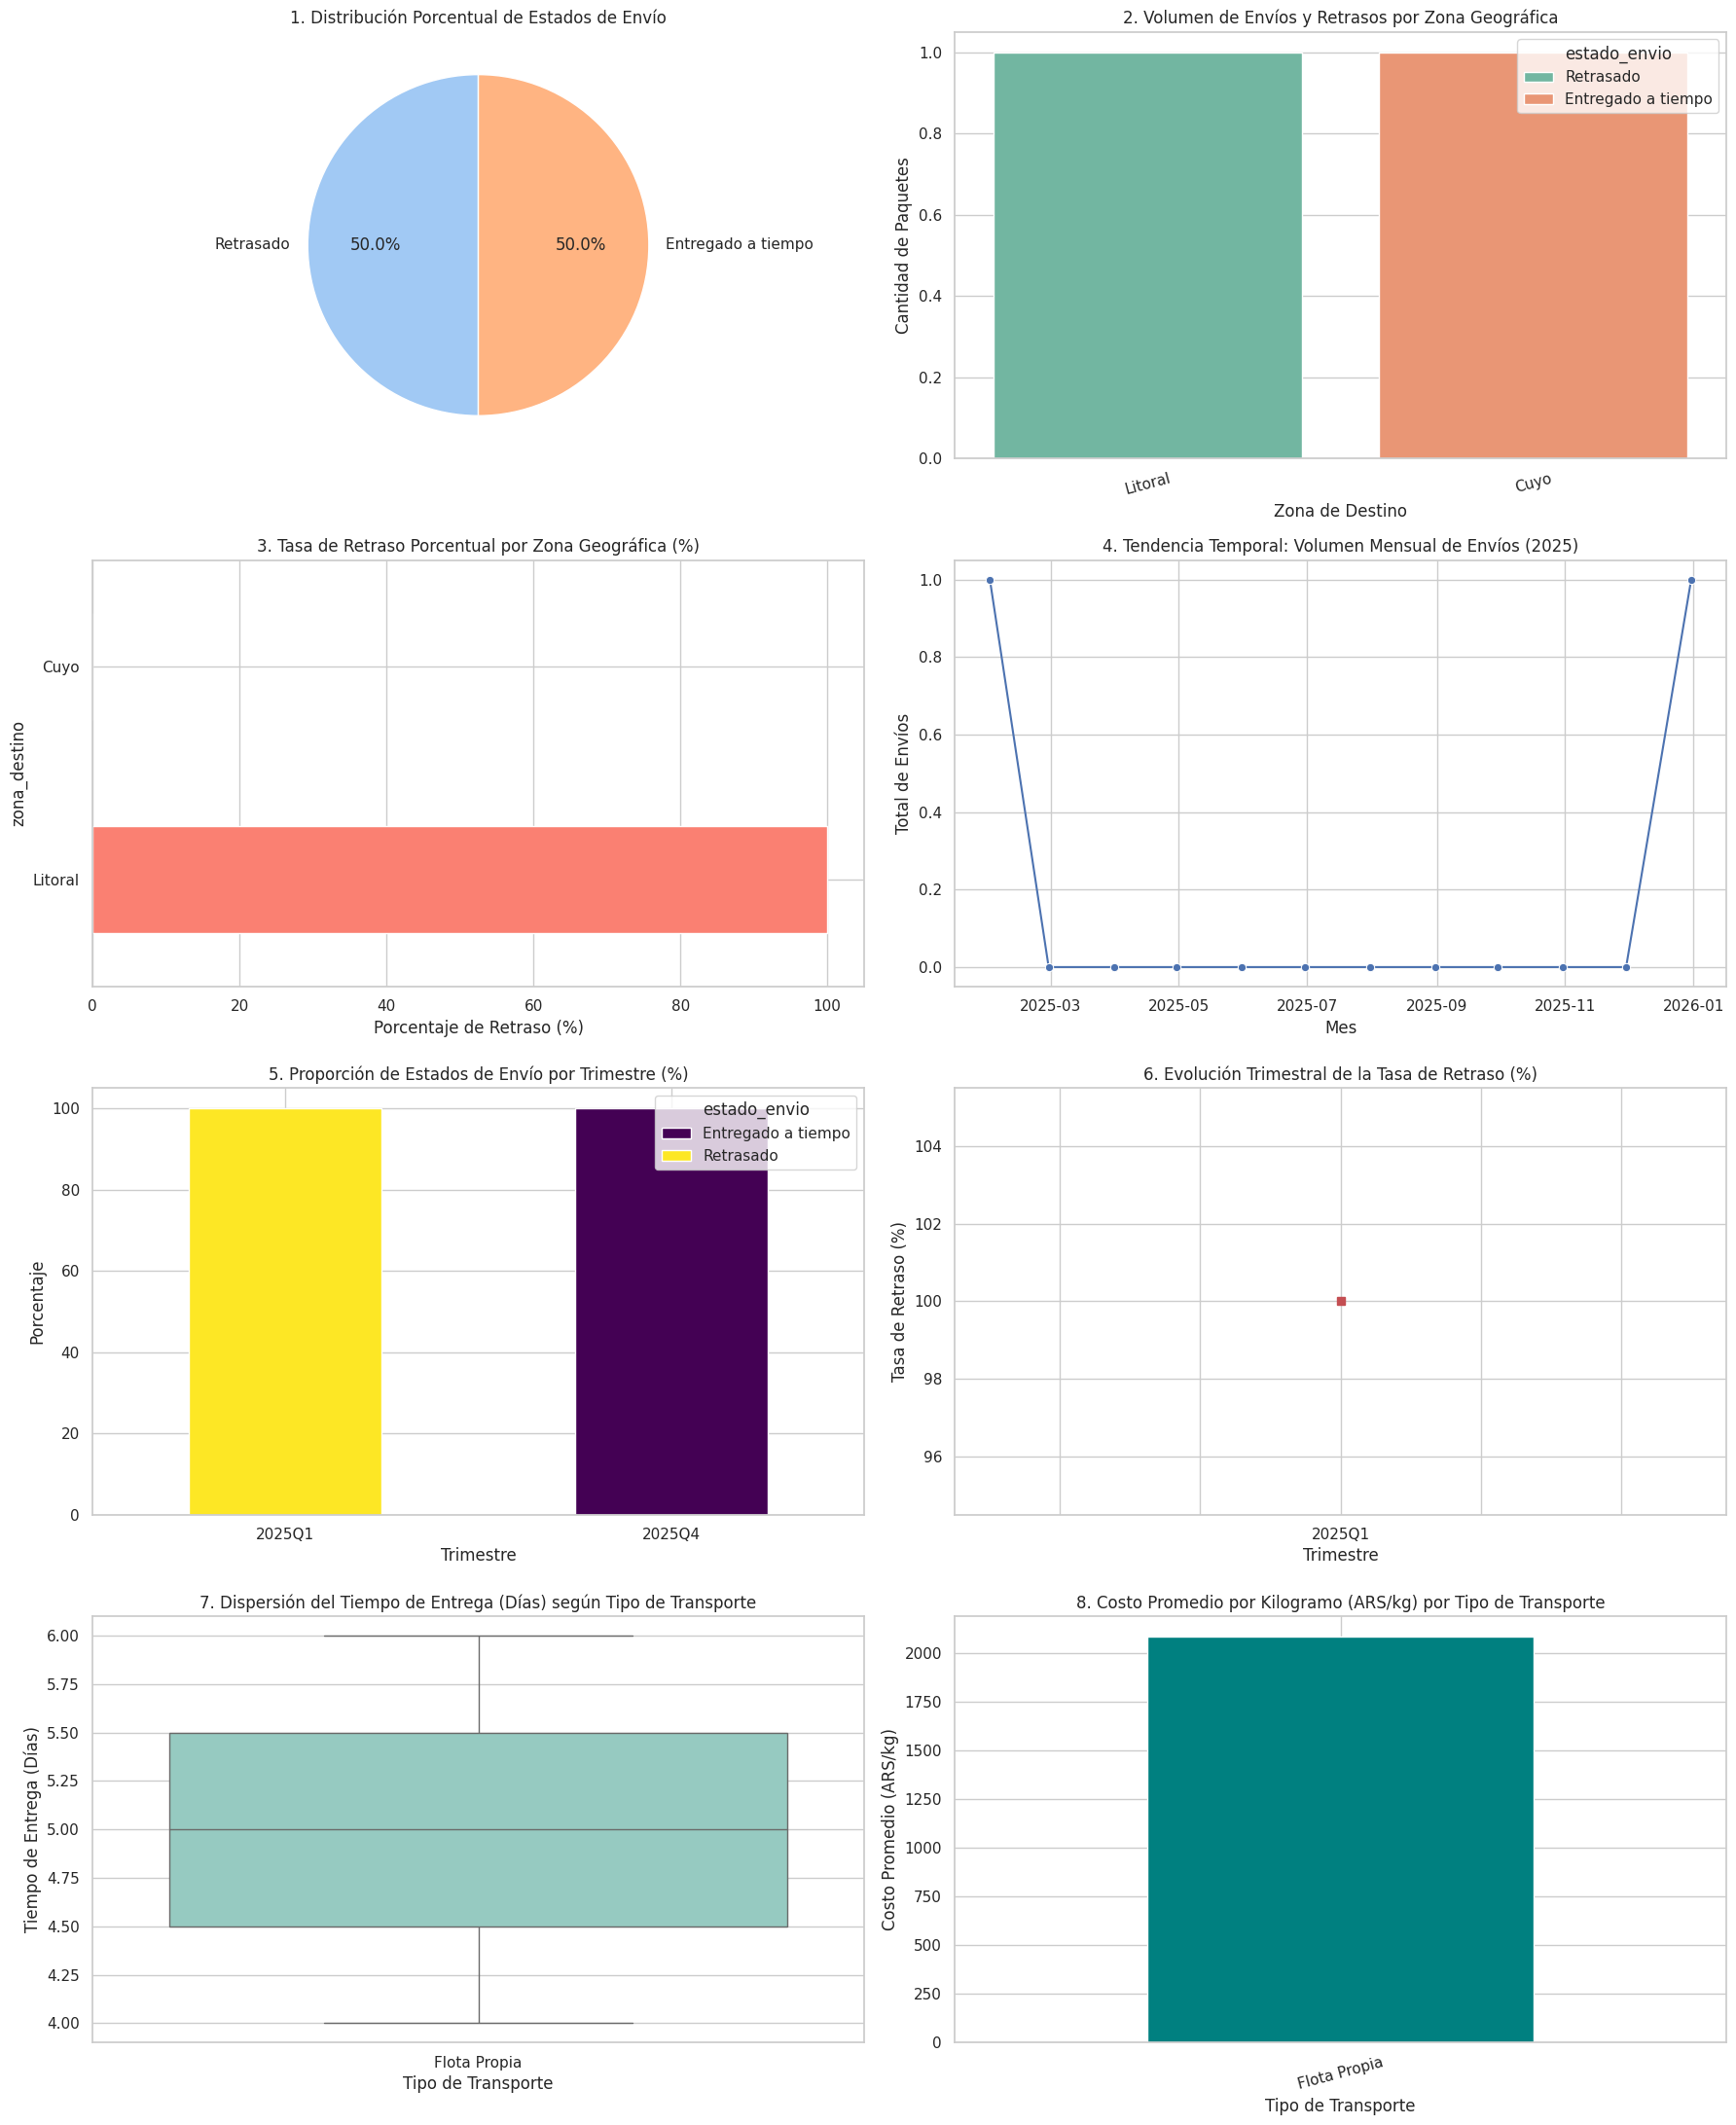

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración estética de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.autolayout": True})

# Cargar el dataset limpio
df = pd.read_csv("envios_ecommerce_limpio.csv")

# Asegurar formato fecha
df["fecha_envio"] = pd.to_datetime(df["fecha_envio"])
df["trimestre"] = df["fecha_envio"].dt.to_period("Q").astype(str)
df["costo_por_kg"] = df["costo_envio"] / df["peso_kg"]

# ==========================================
# GENERACIÓN DE LAS 8 VISUALIZACIONES
# ==========================================

fig = plt.figure(figsize=(18, 22))

# 1. Gráfico de torta: Distribución de estados de envío
ax1 = fig.add_subplot(4, 2, 1)
estado_counts = df["estado_envio"].value_counts()
ax1.pie(
    estado_counts,
    labels=estado_counts.index,
    autopct="%1.1f%%",
    colors=sns.color_palette("pastel"),
    startangle=90,
)
ax1.set_title("1. Distribución Porcentual de Estados de Envío")

# 2. Gráfico de barras: Envíos por zona destino y estado
ax2 = fig.add_subplot(4, 2, 2)
sns.countplot(
    data=df,
    x="zona_destino",
    hue="estado_envio",
    palette="Set2",
    ax=ax2,
    order=df["zona_destino"].value_counts().index,
)
ax2.set_title("2. Volumen de Envíos y Retrasos por Zona Geográfica")
ax2.set_xlabel("Zona de Destino")
ax2.set_ylabel("Cantidad de Paquetes")
plt.xticks(rotation=15)

# 3. Gráfico de barras: Tasa de retraso por zona (%)
ax3 = fig.add_subplot(4, 2, 3)
tasa_zona = (
    df[df["estado_envio"] == "Retrasado"]
    .groupby("zona_destino")
    .size()
    / df.groupby("zona_destino").size()
) * 100
tasa_zona.sort_values().plot(kind="barh", color="salmon", ax=ax3)
ax3.set_title("3. Tasa de Retraso Porcentual por Zona Geográfica (%)")
ax3.set_xlabel("Porcentaje de Retraso (%)")

# 4. Serie temporal: Volumen mensual de envíos
ax4 = fig.add_subplot(4, 2, 4)
df_mensual = (
    df.set_index("fecha_envio").resample("M").size().reset_index(name="total")
)
sns.lineplot(
    data=df_mensual,
    x="fecha_envio",
    y="total",
    marker="o",
    color="b",
    ax=ax4,
)
ax4.set_title("4. Tendencia Temporal: Volumen Mensual de Envíos (2025)")
ax4.set_xlabel("Mes")
ax4.set_ylabel("Total de Envíos")

# 5. Gráfico de barras apiladas: Envíos por Trimestre y Estado
ax5 = fig.add_subplot(4, 2, 5)
trimestre_estado = (
    pd.crosstab(df["trimestre"], df["estado_envio"], normalize="index") * 100
)
trimestre_estado.plot(kind="bar", stacked=True, colormap="viridis", ax=ax5)
ax5.set_title("5. Proporción de Estados de Envío por Trimestre (%)")
ax5.set_xlabel("Trimestre")
ax5.set_ylabel("Porcentaje")
plt.xticks(rotation=0)

# 6. Gráfico de líneas: Evolución trimestral de tasa de retraso
ax6 = fig.add_subplot(4, 2, 6)
tasa_trimestre = (
    df[df["estado_envio"] == "Retrasado"].groupby("trimestre").size()
    / df.groupby("trimestre").size()
) * 100
tasa_trimestre.plot(kind="line", marker="s", color="r", linewidth=2, ax=ax6)
ax6.set_title("6. Evolución Trimestral de la Tasa de Retraso (%)")
ax6.set_xlabel("Trimestre")
ax6.set_ylabel("Tasa de Retraso (%)")

# 7. Boxplot: Dispersión del tiempo de entrega por tipo de transporte
ax7 = fig.add_subplot(4, 2, 7)
sns.boxplot(
    data=df,
    x="tipo_transporte",
    y="tiempo_entrega_dias",
    palette="Set3",
    ax=ax7,
)
ax7.set_title(
    "7. Dispersión del Tiempo de Entrega (Días) según Tipo de Transporte"
)
ax7.set_xlabel("Tipo de Transporte")
ax7.set_ylabel("Tiempo de Entrega (Días)")

# 8. Gráfico de barras: Costo promedio por kilogramo según transporte
ax8 = fig.add_subplot(4, 2, 8)
costo_kg_transporte = df.groupby("tipo_transporte")["costo_por_kg"].mean()
costo_kg_transporte.plot(kind="bar", color="teal", ax=ax8)
ax8.set_title("8. Costo Promedio por Kilogramo (ARS/kg) por Tipo de Transporte")
ax8.set_xlabel("Tipo de Transporte")
ax8.set_ylabel("Costo Promedio (ARS/kg)")
plt.xticks(rotation=15)

plt.savefig("visualizaciones_tp_analisis.png", dpi=300)
print("¡Los 8 gráficos se han generado y guardado con éxito como imagen!")